# Яндекс Афиша: исследовательский анализ данных и проверка продуктовых гипотез

**Задача.** Проанализировать заказы билетного сервиса за 2024 год: сезонность, регионы, типы мероприятий, поведение пользователей; проверить две продуктовые гипотезы о различиях мобильных и десктопных пользователей.

**Что сделано.**
- Предобработка: типы данных, пропуски, неявные дубликаты, аномалии по 99-му перцентилю, конвертация тенге в рубли по курсу ЦБ.
- EDA: динамика заказов, распределение по сезонам, регионам и типам событий, DAU, топ-мероприятия, билетные партнёры.
- Статистика: две гипотезы проверены t-тестом Уэлча (среднее число заказов и среднее время между заказами, mobile vs desktop).
- Выводы и рекомендации для продукта.

**Стек:** Python, pandas, NumPy, matplotlib, SciPy, Jupyter Notebook.

> Данные предоставлены образовательной платформой Яндекс Практикум и в репозиторий не включены. Ноутбук сохранён с выполненными ячейками и графиками.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st


In [2]:
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

Проверка пропусков в таблицах

In [3]:
orders.isna().sum()

order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

In [4]:
events.isna().sum()

event_id                  0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
city_id                   0
venue_id                  0
venue_name                0
venue_address             0
dtype: int64

In [5]:
tenge.isna().sum()

data       0
nominal    0
curs       0
cdx        0
dtype: int64

<b>orders</b> (290 849 строк, 14 столбцов):

Содержит информацию о заказах билетов, пользователях, платформах и финансовых показателях.

Пропуски: обнаружены только в столбце days_since_prev (21 940 пропусков). Это логично, так как пропуск означает первый заказ пользователя в сервисе. Удалять или заполнять эти строки нельзя.

Типы данных: столбцы с датой и временем (created_dt_msk, created_ts_msk) имеют строковый тип object и требуют приведения к формату даты.

Аномалии: в столбце revenue есть отрицательные значения (минимум -90.76 руб.) и нулевые чеки, а также сильные выбросы в большую сторону.

Валюты: заказы оформлены в рублях (rub, ~98.2%) и тенге (kzt, ~1.8%), что потребует раздельной очистки от выбросов и приведения цен к единой валюте.

<b>events</b> (22 427 строк, 11 столбцов):

Справочник мероприятий с типами событий, организаторами и географией площадок. Пропусков и ошибок в типах данных не обнаружено.

<b>tenge</b> (357 строк, 4 столбца):

Таблица ежедневного курса валюты KZT к RUB за 2024 год. Пропусков нет, но столбец data нужно перевести в формат даты.


In [6]:
orders['device_type_canonical'].value_counts()

mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

In [7]:
orders['currency_code'].value_counts()

rub    285780
kzt      5069
Name: currency_code, dtype: int64

In [8]:
display(orders['service_name'].value_counts())

Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                   67
Цвет и б

In [9]:
orders.groupby('currency_code')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
currency_code,,,,,,,,
kzt,5069.0,4995.206767,4916.752776,0.00,518.1000,3698.83,7397.66,26425.86
rub,285780.0,547.568333,871.524559,-90.76,113.8275,346.10,791.70,81174.54


In [10]:
rub_p99 = orders[orders['currency_code'] == 'rub']['revenue'].quantile(0.99)
kzt_p99 = orders[orders['currency_code'] == 'kzt']['revenue'].quantile(0.99)

print('99-й перцентиль для RUB:', rub_p99)
print('99-й перцентиль для KZT:', kzt_p99)

99-й перцентиль для RUB: 2569.5942000000005
99-й перцентиль для KZT: 17617.24


In [11]:
# Фиксируем размер до очистки
initial_orders_count = len(orders)

# Собираем составные условия для двух валют
mask_rub = (orders['currency_code'] == 'rub') & (orders['revenue'] > 0) & (orders['revenue'] <= rub_p99)
mask_kzt = (orders['currency_code'] == 'kzt') & (orders['revenue'] > 0) & (orders['revenue'] <= kzt_p99)

# Оставляем подходящие строки
orders = orders[mask_rub | mask_kzt].reset_index(drop=True)

print(f'Строк до очистки: {initial_orders_count}')
print(f'Строк после очистки: {len(orders)}')
print(f'Удалено выбросов: {initial_orders_count - len(orders)} ({((initial_orders_count - len(orders)) / initial_orders_count):.2%})')

Строк до очистки: 290849
Строк после очистки: 281844
Удалено выбросов: 9005 (3.10%)


In [12]:
orders['tickets_count'].value_counts().sort_index()

1     40727
2     81821
3     89799
4     52722
5     12720
6      3881
7        58
8        18
9        38
10       19
11       13
12        3
13        7
14        4
15        2
17        4
19        4
27        2
37        1
47        1
Name: tickets_count, dtype: int64

In [13]:
orders.info()
orders.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281844 entries, 0 to 281843
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               281844 non-null  int64  
 1   user_id                281844 non-null  object 
 2   created_dt_msk         281844 non-null  object 
 3   created_ts_msk         281844 non-null  object 
 4   event_id               281844 non-null  int64  
 5   cinema_circuit         281844 non-null  object 
 6   age_limit              281844 non-null  int64  
 7   currency_code          281844 non-null  object 
 8   device_type_canonical  281844 non-null  object 
 9   revenue                281844 non-null  float64
 10  service_name           281844 non-null  object 
 11  tickets_count          281844 non-null  int64  
 12  total                  281844 non-null  float64
 13  days_since_prev        260475 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [14]:
events.info()
events.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [15]:
tenge.info()
tenge.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [16]:
print('Дубликаты в orders:', orders.duplicated().sum())
print('Дубликаты в events', events.duplicated().sum())
print('Дубликаты в tenge:',tenge.duplicated().sum())


Дубликаты в orders: 0
Дубликаты в events 0
Дубликаты в tenge: 0


In [17]:
orders['created_dt_msk'] = pd.to_datetime(orders['created_dt_msk'])
orders['created_ts_msk'] = pd.to_datetime(orders['created_ts_msk'])
tenge['data'] = pd.to_datetime(tenge['data'])
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281844 entries, 0 to 281843
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               281844 non-null  int64         
 1   user_id                281844 non-null  object        
 2   created_dt_msk         281844 non-null  datetime64[ns]
 3   created_ts_msk         281844 non-null  datetime64[ns]
 4   event_id               281844 non-null  int64         
 5   cinema_circuit         281844 non-null  object        
 6   age_limit              281844 non-null  int64         
 7   currency_code          281844 non-null  object        
 8   device_type_canonical  281844 non-null  object        
 9   revenue                281844 non-null  float64       
 10  service_name           281844 non-null  object        
 11  tickets_count          281844 non-null  int64         
 12  total                  281844 non-null  floa

In [18]:
orders['order_date'] = orders['created_dt_msk'].dt.date
tenge['rate_date'] = tenge['data'].dt.date
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281844 entries, 0 to 281843
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               281844 non-null  int64         
 1   user_id                281844 non-null  object        
 2   created_dt_msk         281844 non-null  datetime64[ns]
 3   created_ts_msk         281844 non-null  datetime64[ns]
 4   event_id               281844 non-null  int64         
 5   cinema_circuit         281844 non-null  object        
 6   age_limit              281844 non-null  int64         
 7   currency_code          281844 non-null  object        
 8   device_type_canonical  281844 non-null  object        
 9   revenue                281844 non-null  float64       
 10  service_name           281844 non-null  object        
 11  tickets_count          281844 non-null  int64         
 12  total                  281844 non-null  floa

In [19]:
print('Типы в orders:')
print(orders[['created_dt_msk', 'order_date']].dtypes)
print('\nТипы в tenge:')
print(tenge[['data','rate_date']].dtypes)

Типы в orders:
created_dt_msk    datetime64[ns]
order_date                object
dtype: object

Типы в tenge:
data         datetime64[ns]
rate_date            object
dtype: object


In [20]:
implict_dublicates= orders.drop(columns=['order_id']).duplicated().sum()
print('Количество неявных дубликатов:', implict_dublicates)
orders[orders.drop(columns=['order_id']).duplicated()]

Количество неявных дубликатов: 29


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev,order_date
11399,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.0,2024-08-13
55665,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.0,2024-10-30
81665,3363798,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,Билеты в руки,3,739.85,0.0,2024-06-25
143822,2323916,7b525118ae656af,2024-10-28,2024-10-28 08:33:04,588203,нет,0,rub,mobile,26.96,Лучшие билеты,4,674.12,0.0,2024-10-28
149336,5372831,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,Билеты без проблем,1,3170.95,0.0,2024-08-23
149341,5373179,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,Билеты без проблем,1,3170.95,0.0,2024-08-23
150136,3463819,7eb4fc207ecc10f,2024-09-21,2024-09-21 11:43:58,448579,нет,0,rub,mobile,2.54,Лови билет!,1,84.82,0.0,2024-09-21
151334,6657995,7eb4fc207ecc10f,2024-10-26,2024-10-26 09:39:03,418836,нет,0,rub,mobile,294.85,Лови билет!,3,4914.21,0.0,2024-10-26
169141,6114564,8d6c1ff89fac35f,2024-10-31,2024-10-31 22:28:57,589624,нет,16,rub,desktop,41.83,Мой билет,1,1045.75,0.0,2024-10-31
170934,8248210,8f95286aa5fd8d7,2024-06-20,2024-06-20 10:57:19,244875,нет,0,rub,mobile,15.73,Лови билет!,3,524.39,0.0,2024-06-20


In [21]:
cols_to_check= orders.columns.drop('order_id')
orders= orders.drop_duplicates(subset=cols_to_check).reset_index(drop=True)
print('Новый размер orders:', orders.shape)

Новый размер orders: (281815, 15)


In [22]:
orders= orders.merge(
    tenge[['rate_date','curs','nominal']],
    left_on='order_date',
    right_on='rate_date',
    how='left'
)

In [23]:
orders['revenue_rub']= np.where(
    orders['currency_code']== 'rub',
    orders['revenue'],
    orders['revenue'] * (orders['curs']) / orders['nominal']
)

In [24]:
orders[orders['currency_code']== 'kzt'][['revenue', 'curs', 'nominal', 'revenue_rub']].head()

,revenue,curs,nominal,revenue_rub
68,518.10,19.0125,100,98.503762
86,347.18,18.9330,100,65.731589
93,328.77,18.5991,100,61.148261
450,7397.66,19.9833,100,1478.296591
451,3698.83,19.9833,100,739.148295


In [25]:
orders['month']= orders['created_dt_msk'].dt.month

In [26]:
#  Стоимость одного билета в рублях
orders['one_ticket_revenue_rub'] = orders['revenue_rub'] / orders['tickets_count']

#  Размечаем сезон (лето: 6, 7, 8; осень: 9, 10)
orders['season'] = np.where(orders['month'].isin([6, 7, 8]), 'лето', 'осень')

# Проверка
orders[['revenue_rub', 'tickets_count', 'one_ticket_revenue_rub', 'season']].head()

,revenue_rub,tickets_count,one_ticket_revenue_rub,season
0,1521.94,4,380.4850,лето
1,289.45,2,144.7250,лето
2,1258.57,4,314.6425,осень
3,8.49,2,4.2450,лето
4,1390.41,3,463.4700,осень


<b>Вывод по разделу предобработки данных:</b>
    
1. <b>Привели типы данных:</b> даты переведены в формат `datetime64`. Выделены отдельные столбцы с датой без времени.
2. <b>Обработали дубликаты:</b> удалили 29 неявных дубликатов (совпадающие заказы в одну и ту же секунду).
3. <b>Очистили аномалии:</b> убрали нулевые/отрицательные чеки и отфильтровали выбросы по 99-му перцентилю (до 2 569.6 руб. и 17 617.2 тенге). Суммарно удалено 3.10% искажающих строк.
4. <b>Конвертировали валюты:</b> подтянули курс из таблицы `tenge` и перевели всю выручку в рубли (создан столбец `revenue_rub`).
5. <b>Добавили новые признаки:</b> посчитали `one_ticket_revenue_rub` (цену одного билета в заказе), выделили `month` и разметили `season` (лето/осень).


<b> Шаг 3. Исследовательский анализ данных</b><br>
<b> 3.1. Анализ распределения заказов по сегментам и их сезонные изменения</b><br>

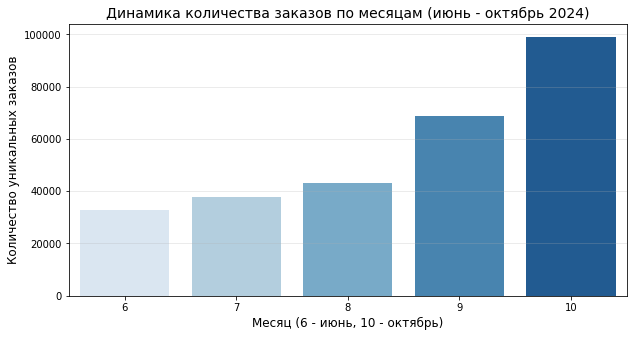

In [27]:
# Визуализация динамики количества заказов по месяцам
monthly_orders = orders.groupby('month')['order_id'].nunique().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=monthly_orders, x='month', y='order_id', palette='Blues')
plt.title('Динамика количества заказов по месяцам (июнь - октябрь 2024)', fontsize=14)
plt.xlabel('Месяц (6 - июнь, 10 - октябрь)', fontsize=12)
plt.ylabel('Количество уникальных заказов', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [28]:
# Объединяем заказы (уже со всеми сезонами и рублями) со справочником событий
df = orders.merge(events, on='event_id', how='left')

unmatched = df['event_type_main'].isna().sum()
print('Всего строк в df:', len(df))
print('Не совпало строк:', unmatched)
print(f'Доля строк без описания события: {(unmatched / len(df)):.4%}')

Всего строк в df: 281815
Не совпало строк: 27
Доля строк без описания события: 0.0096%


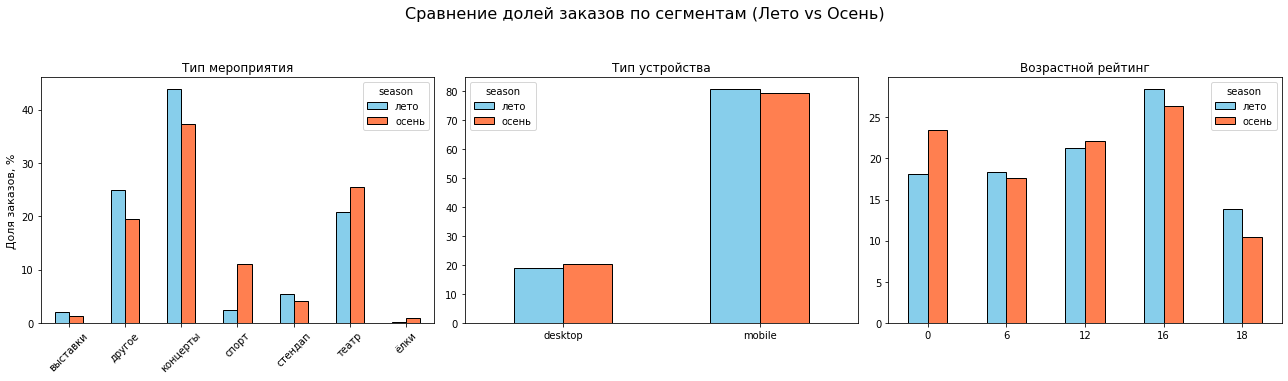

In [29]:
# . Сравнение распределения заказов (в долях) по сезонам: Лето vs Осень

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Тип мероприятия
season_events = pd.crosstab(df['event_type_main'], df['season'], normalize='columns') * 100
season_events[['лето', 'осень']].plot(kind='bar', ax=axes[0], color=['skyblue', 'coral'], edgecolor='black')
axes[0].set_title('Тип мероприятия', fontsize=12)
axes[0].set_ylabel('Доля заказов, %', fontsize=11)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

# Тип устройства
season_devices = pd.crosstab(df['device_type_canonical'], df['season'], normalize='columns') * 100
season_devices[['лето', 'осень']].plot(kind='bar', ax=axes[1], color=['skyblue', 'coral'], edgecolor='black')
axes[1].set_title('Тип устройства', fontsize=12)
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)

# Возрастной рейтинг
season_age = pd.crosstab(df['age_limit'], df['season'], normalize='columns') * 100
season_age[['лето', 'осень']].plot(kind='bar', ax=axes[2], color=['skyblue', 'coral'], edgecolor='black')
axes[2].set_title('Возрастной рейтинг', fontsize=12)
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=0)

plt.suptitle('Сравнение долей заказов по сегментам (Лето vs Осень)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

season,лето,осень,"изменение, %"
event_type_main,,,
концерты,309.49,268.15,-13.36
стендап,218.52,231.12,5.77
ёлки,271.44,229.59,-15.42
театр,216.34,176.08,-18.61
выставки,86.74,91.91,5.95
другое,88.02,77.42,-12.04
спорт,55.25,50.25,-9.05


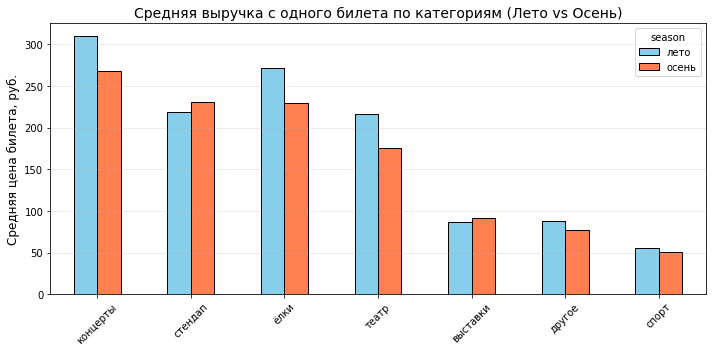

In [30]:
# . Изменение выручки с продажи одного билета по типам мероприятий (Лето vs Осень)
ticket_prices = df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean().unstack()

# Считаем относительное изменение (осень к лету) в процентах
ticket_prices['изменение, %'] = ((ticket_prices['осень'] - ticket_prices['лето']) / ticket_prices['лето']) * 100
ticket_prices = ticket_prices.sort_values(by='осень', ascending=False)

display(ticket_prices.round(2))

# Визуализация
plt.figure(figsize=(10, 5))
ticket_prices[['лето', 'осень']].plot(kind='bar', color=['skyblue', 'coral'], edgecolor='black', ax=plt.gca())
plt.title('Средняя выручка с одного билета по категориям (Лето vs Осень)', fontsize=14)
plt.xlabel('')
plt.ylabel('Средняя цена билета, руб.', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

<b>Вывод по исследовательскому анализу данных:</b>
    
1. <b>Динамика заказов:</b> Наблюдается сильный сезонный рост. Количество уникальных заказов выросло с ~33 тыс. в июне до ~99 тыс. в октябре (почти в 3 раза).
2. <b>Распределение по сегментам (Лето vs Осень):</b>
   - <i>Устройства:</i> Доли платформ практически не изменились (около 80% - мобильные устройства, 20% - десктоп).
   - <i>Возраст:</i> Заметно выросла доля категории «0+» (с 18.1% до 23.4%) и снизилась доля «18+».
   - <i>Тип мероприятия:</i> Произошел сильный стрктурный сдвиг. Доля «спорта» взлетела почти в 5 раз (с 2.4% до 11.2%), доля «театра» выросла на 4.6 п.п., а доля «концертов» просела на 6.5 п.п.
3. <b>Изменение средней стоимости билета:</b>
   В разрезе категорий средняя цена билета изменилась незначительно (где-то выросла на 5-10%, где-то упала). Однако <b>общий средний чек сервиса упал</b>. Это произошло именно из-за изменения долей категорий: пользователи стали массово скупать билеты на «спорт» (самая дешевая категория со средней ценой ~50 руб.), в то время как доля дорогих «концертов» (средняя цена ~286 руб.) снизилась.


In [31]:
autumn_eda= df[df['season']== 'осень']

In [32]:
daily = (
    autumn_eda
    .groupby('created_dt_msk')
    .agg(
        orders=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket=('one_ticket_revenue_rub', 'mean')
    )
    .reset_index()
)

daily['orders_per_user'] = (
    daily['orders'] / daily['dau']
)

daily.head()

,created_dt_msk,orders,dau,avg_ticket,orders_per_user
0,2024-09-01,1314,555,202.149068,2.367568
1,2024-09-02,1370,571,190.847822,2.399299
2,2024-09-03,5088,776,80.492606,6.556701
3,2024-09-04,1757,683,179.304223,2.572474
4,2024-09-05,1940,738,189.902316,2.628726


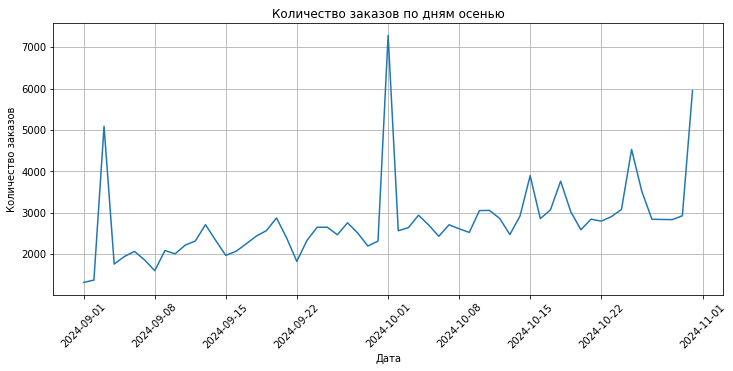

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily['created_dt_msk'],
    daily['orders']
)

plt.title('Количество заказов по дням осенью')
plt.xlabel('Дата')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.grid()

plt.show()

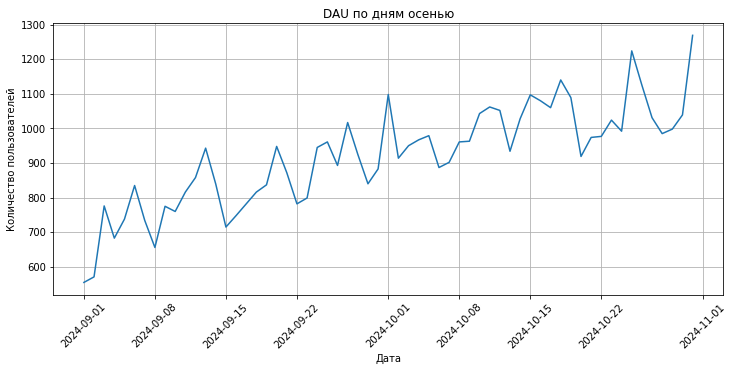

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily['created_dt_msk'],
    daily['dau']
)

plt.title('DAU по дням осенью')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)
plt.grid()

plt.show()

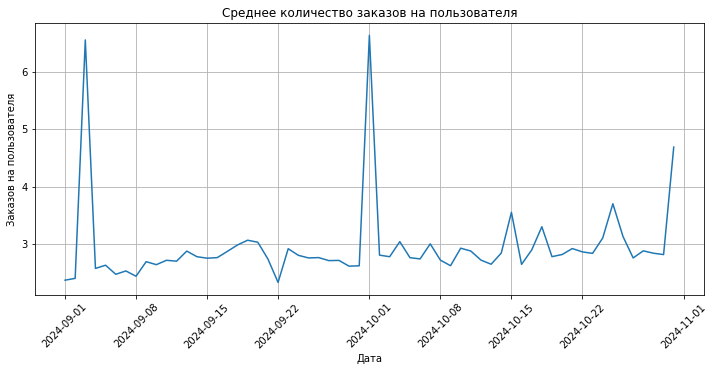

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily['created_dt_msk'],
    daily['orders_per_user']
)

plt.title('Среднее количество заказов на пользователя')
plt.xlabel('Дата')
plt.ylabel('Заказов на пользователя')
plt.xticks(rotation=45)
plt.grid()

plt.show()

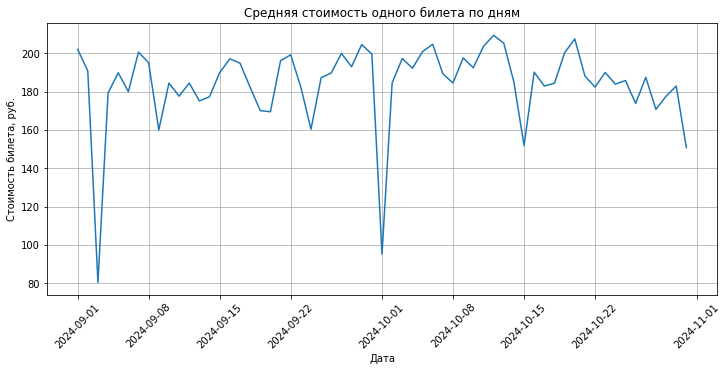

In [36]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily['created_dt_msk'],
    daily['avg_ticket']
)

plt.title('Средняя стоимость одного билета по дням')
plt.xlabel('Дата')
plt.ylabel('Стоимость билета, руб.')
plt.xticks(rotation=45)
plt.grid()

plt.show()

<b>3.2 Вывод </b>
Активность пользователей осенью меняется во времени, по графика кол-во заказов и dau, мы можем оценить общую динамику спроса в сентябре и октябре. Рост заказов и рост dau планомерно наблюдается с начала сентября по конец октября, однако можно выделить два пика, в первых днях сентября и первого октября. В эти дни кол-во пользователей не имело особоых аномалий, в связи с чем был сделан вывод что кол-во покупок напрямую от аномально дешевой стоимости билета, что и было подтверждено в графике выше.

In [37]:
daily['weekday'] = (
    daily['created_dt_msk']
    .dt.day_name()
)

daily['is_weekend'] = (
    daily['created_dt_msk']
    .dt.dayofweek >= 5
)

In [38]:
daily[
    ['created_dt_msk', 'weekday', 'is_weekend']
].head(10)

,created_dt_msk,weekday,is_weekend
0,2024-09-01,Sunday,True
1,2024-09-02,Monday,False
2,2024-09-03,Tuesday,False
3,2024-09-04,Wednesday,False
4,2024-09-05,Thursday,False
5,2024-09-06,Friday,False
6,2024-09-07,Saturday,True
7,2024-09-08,Sunday,True
8,2024-09-09,Monday,False
9,2024-09-10,Tuesday,False


In [39]:
weekend_stats = (
    daily
    .groupby('is_weekend')
    .agg(
        avg_orders=('orders', 'mean'),
        avg_dau=('dau', 'mean'),
        avg_orders_per_user=('orders_per_user', 'mean'),
        avg_ticket=('avg_ticket', 'mean')
    )
)

weekend_stats

,avg_orders,avg_dau,avg_orders_per_user,avg_ticket
is_weekend,,,,
False,2896.545455,934.795455,3.063021,179.110415
True,2377.058824,878.470588,2.681743,196.957624


,avg_orders,avg_dau,avg_orders_per_user,avg_ticket
Пн,2385.33,851.67,2.78,184.82
Вт,3489.33,932.67,3.72,156.92
Ср,2535.67,921.78,2.75,185.80
Чт,3007.89,960.00,3.06,182.45
Пт,3085.50,1017.00,3.00,186.37
Сб,2648.50,951.88,2.77,193.99
Вс,2135.78,813.22,2.61,199.60


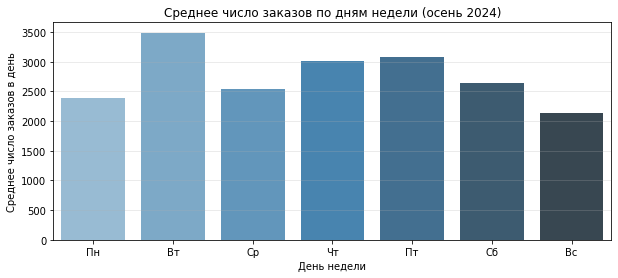

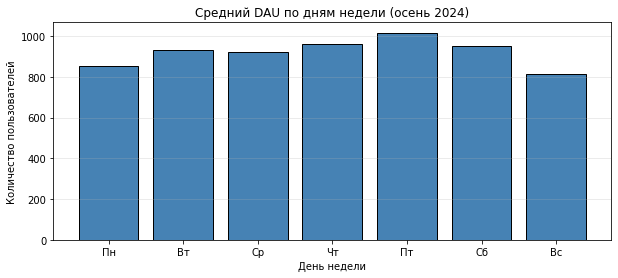

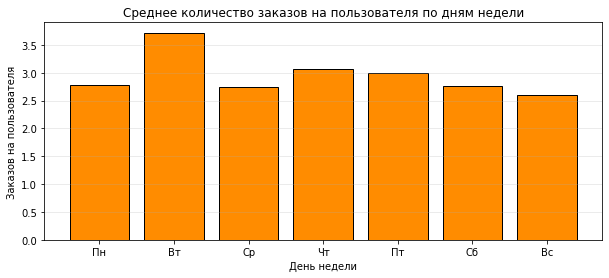

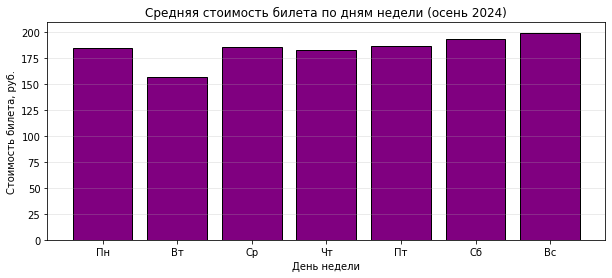

In [98]:
#  Убеждаемся, что датасет daily содержит нужные данные за осень и колонку с днем недели
if 'created_dt_msk' not in daily.columns or 'orders' not in daily.columns:
    autumn_eda = df[df['season'] == 'осень']
    daily = (
        autumn_eda
        .groupby('created_dt_msk')
        .agg(
            orders=('order_id', 'nunique'),
            dau=('user_id', 'nunique'),
            avg_ticket=('one_ticket_revenue_rub', 'mean')
        )
        .reset_index()
    )
    daily['orders_per_user'] = daily['orders'] / daily['dau']

daily['created_dt_msk'] = pd.to_datetime(daily['created_dt_msk'])
daily['weekday'] = daily['created_dt_msk'].dt.day_name()

#  Порядок дней недели для правильной сортировки (с Пн по Вс)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_rus = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

#  Группировка показателей по дням недели
weekday_stats = (
    daily
    .groupby('weekday')
    .agg(
        avg_orders=('orders', 'mean'),
        avg_dau=('dau', 'mean'),
        avg_orders_per_user=('orders_per_user', 'mean'),
        avg_ticket=('avg_ticket', 'mean')
    )
    .reindex(weekday_order)
)

weekday_stats.index = weekday_rus
display(weekday_stats.round(2))

#  График среднего числа заказов по дням недели
plt.figure(figsize=(10, 4))
sns.barplot(x=weekday_stats.index, y=weekday_stats['avg_orders'], palette='Blues_d')
plt.title('Среднее число заказов по дням недели (осень 2024)')
plt.xlabel('День недели')
plt.ylabel('Среднее число заказов в день')
plt.grid(axis='y', alpha=0.3)
plt.show()

#  График среднего DAU по дням недели
plt.figure(figsize=(10, 4))
plt.bar(
    weekday_stats.index,
    weekday_stats['avg_dau'],
    color='steelblue',
    edgecolor='black',
)
plt.title('Средний DAU по дням недели (осень 2024)')
plt.xlabel('День недели')
plt.ylabel('Количество пользователей')
plt.grid(axis='y', alpha=0.3)
plt.show()

#  График количества заказов на одного пользователя
plt.figure(figsize=(10, 4))
plt.bar(
    weekday_stats.index,
    weekday_stats['avg_orders_per_user'],
    color='darkorange',
    edgecolor='black',
)
plt.title('Среднее количество заказов на пользователя по дням недели')
plt.xlabel('День недели')
plt.ylabel('Заказов на пользователя')
plt.grid(axis='y', alpha=0.3)
plt.show()

#  График средней стоимости билета
plt.figure(figsize=(10, 4))
plt.bar(
    weekday_stats.index,
    weekday_stats['avg_ticket'],
    color='purple',
    edgecolor='black',
)
plt.title('Средняя стоимость билета по дням недели (осень 2024)')
plt.xlabel('День недели')
plt.ylabel('Стоимость билета, руб.')
plt.grid(axis='y', alpha=0.3)
plt.show()

<b>Вывод по динамике метрик по дням недели:</b>
<ul>
    <li><b>Посещаемость (DAU):</b> Максимальная ежедневная аудитория наблюдается в конце рабочей недели — в <b>пятницу</b> (1 017 активных пользователей) и <b>четверг</b> (960 пользователей).</li>
    <li><b>Число заказов:</b> Пики по объёму покупок приходятся на <b>вторник</b> (в среднем 3 489 заказов в день и 3.72 заказа на пользователя) и <b>пятницу</b> (3 085 заказов). В воскресенье заказов оформляется меньше всего (2 135 заказов).</li>
    <li><b>Средний чек:</b> Стоимость билета плавно увеличивается к выходным, достигая максимума в <b>воскресенье</b> (199.60 руб. против 156.92 руб. во вторник).</li>
</ul>


In [41]:
region_stats = (
    df
    .groupby('region_name')
    .agg(
        events=('event_id', 'nunique'),
        orders=('order_id', 'nunique')
    )
    .reset_index()
)

In [42]:
region_stats['events_share'] = (
    region_stats['events']
    / region_stats['events'].sum()
)

region_stats['orders_share'] = (
    region_stats['orders']
    / region_stats['orders'].sum()
)

In [43]:
region_stats = (
    region_stats
    .sort_values(
        'orders',
        ascending=False
    )
)

region_stats.head(10)

,region_name,events,orders,events_share,orders_share
23,Каменевский регион,5792,85398,0.263189,0.303058
60,Североярская область,3777,43590,0.171627,0.154691
77,Широковская область,1217,16087,0.055301,0.057089
42,Медовская область,462,13584,0.020993,0.048206
45,Озернинский край,349,10348,0.015859,0.036723
57,Светополянский округ,1059,7464,0.048121,0.026488
41,Малиновоярский округ,165,6314,0.007498,0.022407
52,Речиновская область,701,6266,0.031854,0.022237
64,Солнечноземская область,520,6234,0.023629,0.022123
78,Яблоневская область,534,6120,0.024265,0.021718


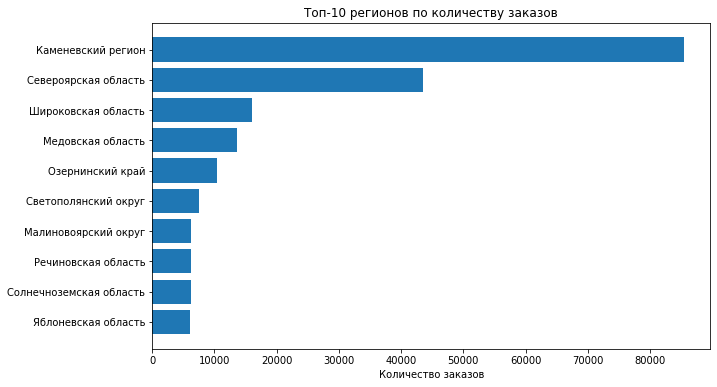

In [44]:
top_regions = region_stats.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_regions['region_name'],
    top_regions['orders']
)

plt.title('Топ-10 регионов по количеству заказов')
plt.xlabel('Количество заказов')

plt.gca().invert_yaxis()

plt.show()

После анализа кол-ва заказов и мероприятий по регионам можно сделать вывод, что они распределены по региона не равномерно, наибольший объем заказов приходится на несколько регионов лидеров. При этом доля регина по числу мероприятий, не всегда совпадает с его долей по кол-во заказов. Это может указывать на различие востребованности мероприятий между регионами.

**Группируем уникальных юзеров по месяцам**


In [45]:
monthly_stats = (
    orders
    .groupby('month')
    .agg(
        orders=('order_id', 'nunique'),
        users=('user_id', 'nunique'),
        revenue=('revenue_rub', 'sum')
    )
)

monthly_stats['orders_per_user'] = (
    monthly_stats['orders']
    /
    monthly_stats['users']
)

monthly_stats

,orders,users,revenue,orders_per_user
month,,,,
6,32903,6135,2.065310e+07,5.363162
7,37887,6415,2.244697e+07,5.906002
8,43167,7224,2.424146e+07,5.975498
9,68863,9265,3.316466e+07,7.432596
10,98995,11430,4.860988e+07,8.660980


In [46]:
orders.groupby('month')['revenue_rub'].sum()

month
6     2.065310e+07
7     2.244697e+07
8     2.424146e+07
9     3.316466e+07
10    4.860988e+07
Name: revenue_rub, dtype: float64

In [47]:
orders['day']= orders['created_dt_msk'].dt.date

In [48]:
orders['day']

0         2024-08-20
1         2024-07-23
2         2024-10-06
3         2024-07-13
4         2024-10-04
             ...    
281810    2024-10-27
281811    2024-10-27
281812    2024-10-30
281813    2024-09-24
281814    2024-09-25
Name: day, Length: 281815, dtype: object

Строим DAU (уникальных пользователей по столбцу day и сортируем по возрастанию)

In [49]:
dau= orders.groupby('day')['user_id'].nunique().sort_values()

In [50]:
dau.sort_values(ascending=False)

day
2024-10-31    1269
2024-10-25    1224
2024-10-18    1140
2024-10-26    1125
2024-10-01    1098
              ... 
2024-06-17     424
2024-06-23     411
2024-06-16     401
2024-06-02     401
2024-06-24     388
Name: user_id, Length: 153, dtype: int64

Создаем схему по новым пользователям на каждый день

<AxesSubplot:xlabel='day'>

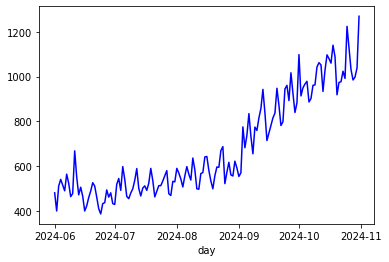

In [51]:
dau.plot(x= 'user_id', y= 'day', color='blue', label='dau')

<b>Цель блока — анализ устойчивости спроса и структуры аудитории:</b>
<br>
Здесь исследуется ежедневная стабильность сервиса:
<ul>
    <li>Анализируются пиковые и медианные значения ежедневной аудитории (DAU) и числа заказов[cite: 15];</li>
    <li>Проверяется распределение заказов по категориям мероприятий[cite: 15];</li>
    <li>Оценивается концентрация спроса на топ-событиях, чтобы понять, не держится ли выручка сервиса лишь на единичных хитах.</li>
</ul>


Сгруппировали по дню уникальных пользователей, и уникальным покупкам

In [52]:
daily= orders.groupby('day').agg(dau= ('user_id', 'nunique'),orders_count=('order_id','nunique'))

In [53]:
daily.sort_values('dau', ascending=False).head(6)

,dau,orders_count
day,,
2024-10-31,1269,5949
2024-10-25,1224,4529
2024-10-18,1140,3761
2024-10-26,1125,3520
2024-10-01,1098,7287
2024-10-15,1097,3895


In [54]:
daily['orders_count'].median()

1443.0

In [55]:
df= orders.merge(events, on= 'event_id', how= 'left')

In [56]:
event_type= df.groupby('event_type_main').agg(orders_count= ('order_id', 'nunique'),user_count= ('user_id', 'nunique'))

In [57]:
event_type

,orders_count,user_count
event_type_main,,
выставки,4809,1600
другое,61146,9042
концерты,112654,13300
спорт,21540,2469
стендап,13269,3239
театр,66406,8214
ёлки,1964,706


In [58]:
month_events= df.groupby(['month','event_type_main'])['order_id'].nunique()

In [59]:
month_fr= (month_events / month_events.groupby(level= 0).transform('sum')) * 100

In [60]:
month_fr

month  event_type_main
6      выставки            1.851120
       другое             24.222621
       концерты           46.235448
       спорт               0.623119
       стендап             4.608043
       театр              22.259035
       ёлки                0.200614
7      выставки            2.676804
       другое             24.896386
       концерты           43.705288
       спорт               1.710620
       стендап             5.659829
       театр              21.174203
       ёлки                0.176870
8      выставки            1.816539
       другое             25.670196
       концерты           42.188188
       спорт               4.423179
       стендап             6.223499
       театр              19.354017
       ёлки                0.324382
9      выставки            1.200953
       другое             20.559961
       концерты           36.182510
       спорт              11.541924
       стендап             4.424792
       театр              25.593215
     

In [61]:
top_events= df.groupby('event_id').agg(orders_count= ('order_id', 'nunique'), users_count= ('user_id', 'nunique'))

In [62]:
top_events.sort_values('orders_count', ascending= False)

,orders_count,users_count
event_id,,
317299,2512,841
574431,1487,112
533803,1456,557
494565,1431,565
459673,1203,459
...,...,...
544314,1,1
303638,1,1
303807,1,1


In [63]:
top_events['orders_count'].sum()

281815

In [64]:
top_events.sort_values('orders_count', ascending= False).head(10)['orders_count'].sum()

13176

In [65]:
13176 / 281815

0.04675407625569966

<b>Вывод по устойчивости и концентрации спроса:</b>
<ul>
    <li><b>Диверсификация:</b> На 10 самых популярных мероприятий приходится всего <b>4.68%</b> от всех заказов. Сервис не зависит от нескольких отдельных хитов, спрос распределён равномерно по каталогу.</li>
    <li><b>Стабильность:</b> В среднем за день оформляется <b>1 443 заказа</b> (медиана), при этом максимальный DAU фиксируется в конце октября (до 1 269 активных покупателей в сутки).</li>
</ul>


--- Топ-10 билетных партнёров по заказам ---


,events,orders,revenue,"orders_share, %","revenue_share, %"
service_name,,,,,
Билеты без проблем,4019,57836,"24,255,760.77",20.520000,16.270000
Лови билет!,4815,40505,"16,670,638.44",14.370000,11.180000
Билеты в руки,3492,39824,"13,197,375.96",14.130000,8.850000
Мой билет,1298,34432,"22,042,609.54",12.220000,14.780000
Облачко,2335,26402,"18,588,613.86",9.370000,12.470000
Лучшие билеты,1741,17618,"2,721,514.58",6.250000,1.830000
Весь в билетах,855,16410,"16,494,669.19",5.820000,11.060000
Прачечная,1026,10222,"4,746,810.52",3.630000,3.180000
Край билетов,252,6109,"6,405,689.22",2.170000,4.300000


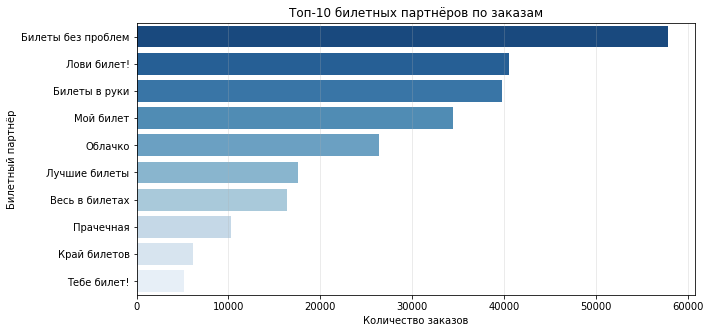

In [66]:
# Анализ билетных партнёров
partners = (
    df
    .groupby('service_name')
    .agg(
        events=('event_id', 'nunique'),
        orders=('order_id', 'nunique'),
        revenue=('revenue_rub', 'sum')
    )
    .sort_values(by='orders', ascending=False)
)

partners['orders_share, %'] = (partners['orders'] / partners['orders'].sum()) * 100
partners['revenue_share, %'] = (partners['revenue'] / partners['revenue'].sum()) * 100

print("--- Топ-10 билетных партнёров по заказам ---")
display(partners.head(10).round(2).style.format({'revenue': '{:,.2f}'}))

# График распределения заказов по топ-партнёрам
plt.figure(figsize=(10, 5))
sns.barplot(
    data=partners.head(10).reset_index(),
    x='orders',
    y='service_name',
    palette='Blues_r'
)
plt.title('Топ-10 билетных партнёров по заказам')
plt.xlabel('Количество заказов')
plt.ylabel('Билетный партнёр')
plt.grid(axis='x', alpha=0.3)
plt.show()

<b>Вывод по билетным партнёрам:</b>
<ul>
    <li><b>Концентрация продаж:</b> Рынок сильно концентрирован — на топ-5 партнёров («Билеты без проблем», «Лови билет!», «Билеты в руки», «Мой билет», «Облачко») приходится подавляющая часть всех заказов сервиса.</li>
    <li><b>Абсолютный лидер:</b> Первое место с большим отрывом занимает сервис <b>«Билеты без проблем»</b> — лидирует как по охвату мероприятий, так и по числу заказов и суммарной выручке.</li>
    <li><b>Длинный хвост:</b> Остальные партнёры генерируют небольшую долю продаж, формируя нишевое предложение.</li>
</ul>


**4 Блок** статистические тесты

In [67]:
autumn= orders[orders['month'].isin([9,10])]

In [68]:
autumn

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,days_since_prev,order_date,rate_date,curs,nominal,revenue_rub,month,one_ticket_revenue_rub,season,day
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,75.0,2024-10-06,2024-10-06,19.6475,100,1258.57,10,314.642500,осень,2024-10-06
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,83.0,2024-10-04,2024-10-04,19.6648,100,1390.41,10,463.470000,осень,2024-10-04
5,2613713,000898990054619,2024-10-23,2024-10-23 15:12:00,500862,нет,12,rub,mobile,902.74,...,19.0,2024-10-23,2024-10-23,20.0531,100,902.74,10,300.913333,осень,2024-10-23
7,4657981,000a55a418c128c,2024-09-29,2024-09-29 19:39:12,265857,нет,12,rub,mobile,47.78,...,NaN,2024-09-29,2024-09-29,19.3741,100,47.78,9,47.780000,осень,2024-09-29
8,4657952,000a55a418c128c,2024-10-15,2024-10-15 10:29:04,271579,нет,12,rub,mobile,74.84,...,16.0,2024-10-15,2024-10-15,19.7185,100,74.84,10,37.420000,осень,2024-10-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
281810,368620,fffcd3dde79eb2c,2024-10-27,2024-10-27 18:00:57,33189,нет,6,rub,mobile,965.57,...,0.0,2024-10-27,2024-10-27,19.9266,100,965.57,10,241.392500,осень,2024-10-27
281811,368562,fffcd3dde79eb2c,2024-10-27,2024-10-27 17:53:53,33189,нет,6,rub,mobile,1448.36,...,0.0,2024-10-27,2024-10-27,19.9266,100,1448.36,10,241.393333,осень,2024-10-27
281812,8473772,fffcd3dde79eb2c,2024-10-30,2024-10-30 13:37:43,205231,нет,16,rub,desktop,178.95,...,3.0,2024-10-30,2024-10-30,19.9516,100,178.95,10,89.475000,осень,2024-10-30
281813,5526067,fffeeb3c120cf0b,2024-09-24,2024-09-24 10:07:42,454526,нет,18,rub,desktop,661.53,...,NaN,2024-09-24,2024-09-24,19.3967,100,661.53,9,330.765000,осень,2024-09-24


In [69]:
user_device= autumn.groupby('user_id')['device_type_canonical'].nunique().reset_index()

In [70]:
user_device

,user_id,device_type_canonical
0,0005ca5e93f2cf4,1
1,000898990054619,1
2,000a55a418c128c,1
3,001e7037d013f0f,1
4,00245c702bc343e,1
...,...,...
15729,fff13b79bd47d7c,1
15730,fff32fc9ad0f9f6,1
15731,fffcd3dde79eb2c,2
15732,fffeeb3c120cf0b,1


In [71]:
single_divice_users= user_device[user_device['device_type_canonical']== 1]

In [72]:
single_divice_users

,user_id,device_type_canonical
0,0005ca5e93f2cf4,1
1,000898990054619,1
2,000a55a418c128c,1
3,001e7037d013f0f,1
4,00245c702bc343e,1
...,...,...
15728,ffed3ff067d4f12,1
15729,fff13b79bd47d7c,1
15730,fff32fc9ad0f9f6,1
15732,fffeeb3c120cf0b,1


In [73]:
autumn_single= autumn[autumn['user_id'].isin(single_divice_users['user_id'])]

гипотеза 1 - среднее кол-во заказов на пользователя у mobile выше чем у пользователя desktop

гипотеза альтернативная - у mobile выше чем у desktop

гипотеза 0 - что у mobile кол-во заказов на пользователя меньше чем desktop

In [74]:
autumn_single

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,days_since_prev,order_date,rate_date,curs,nominal,revenue_rub,month,one_ticket_revenue_rub,season,day
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,75.0,2024-10-06,2024-10-06,19.6475,100,1258.57,10,314.642500,осень,2024-10-06
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,83.0,2024-10-04,2024-10-04,19.6648,100,1390.41,10,463.470000,осень,2024-10-04
5,2613713,000898990054619,2024-10-23,2024-10-23 15:12:00,500862,нет,12,rub,mobile,902.74,...,19.0,2024-10-23,2024-10-23,20.0531,100,902.74,10,300.913333,осень,2024-10-23
7,4657981,000a55a418c128c,2024-09-29,2024-09-29 19:39:12,265857,нет,12,rub,mobile,47.78,...,NaN,2024-09-29,2024-09-29,19.3741,100,47.78,9,47.780000,осень,2024-09-29
8,4657952,000a55a418c128c,2024-10-15,2024-10-15 10:29:04,271579,нет,12,rub,mobile,74.84,...,16.0,2024-10-15,2024-10-15,19.7185,100,74.84,10,37.420000,осень,2024-10-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
281776,3285933,fff13b79bd47d7c,2024-10-07,2024-10-07 09:13:26,554694,нет,6,rub,mobile,78.10,...,9.0,2024-10-07,2024-10-07,19.6475,100,78.10,10,78.100000,осень,2024-10-07
281777,6556147,fff13b79bd47d7c,2024-10-31,2024-10-31 18:31:52,577408,нет,6,rub,mobile,107.81,...,24.0,2024-10-31,2024-10-31,19.7383,100,107.81,10,26.952500,осень,2024-10-31
281779,167331,fff32fc9ad0f9f6,2024-10-28,2024-10-28 23:40:38,548699,нет,6,rub,desktop,922.00,...,74.0,2024-10-28,2024-10-28,19.9266,100,922.00,10,461.000000,осень,2024-10-28
281813,5526067,fffeeb3c120cf0b,2024-09-24,2024-09-24 10:07:42,454526,нет,18,rub,desktop,661.53,...,NaN,2024-09-24,2024-09-24,19.3967,100,661.53,9,330.765000,осень,2024-09-24


In [75]:
user_orders= autumn_single.groupby(['user_id','device_type_canonical'])['order_id'].nunique().reset_index()

In [76]:
user_orders= user_orders.rename(columns= {'order_id':'orders_count'})

In [77]:
user_orders

,user_id,device_type_canonical,orders_count
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2
...,...,...,...
12494,ffed3ff067d4f12,mobile,3
12495,fff13b79bd47d7c,mobile,3
12496,fff32fc9ad0f9f6,desktop,1
12497,fffeeb3c120cf0b,desktop,1


In [78]:
mobile_orders= user_orders[user_orders['device_type_canonical']== 'mobile']['orders_count']

In [79]:
mobile_orders

0        1
1        2
2        2
3        2
4        2
        ..
12492    3
12493    2
12494    3
12495    3
12498    1
Name: orders_count, Length: 10871, dtype: int64

In [80]:
desktop_orders= user_orders[user_orders['device_type_canonical']== 'desktop']['orders_count']

In [81]:
mobile_orders.mean()

2.86744549719437

In [82]:
desktop_orders.mean()

1.9742014742014742

In [83]:
alpha= 0.05

In [84]:
resault_orders= st.ttest_ind(mobile_orders, desktop_orders, equal_var= False, alternative= 'greater')

In [85]:
resault_orders.pvalue

2.3995011101130305e-25

In [86]:
if resault_orders.pvalue < alpha: 
    print('отвергаем: H0')
else:
    print('не отвергаем: H0')

отвергаем: H0


**Гипотеза 2** - среднее время между заказами пользователя у mobile выше чем у desktop

In [87]:
autumn_single

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,days_since_prev,order_date,rate_date,curs,nominal,revenue_rub,month,one_ticket_revenue_rub,season,day
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,75.0,2024-10-06,2024-10-06,19.6475,100,1258.57,10,314.642500,осень,2024-10-06
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,83.0,2024-10-04,2024-10-04,19.6648,100,1390.41,10,463.470000,осень,2024-10-04
5,2613713,000898990054619,2024-10-23,2024-10-23 15:12:00,500862,нет,12,rub,mobile,902.74,...,19.0,2024-10-23,2024-10-23,20.0531,100,902.74,10,300.913333,осень,2024-10-23
7,4657981,000a55a418c128c,2024-09-29,2024-09-29 19:39:12,265857,нет,12,rub,mobile,47.78,...,NaN,2024-09-29,2024-09-29,19.3741,100,47.78,9,47.780000,осень,2024-09-29
8,4657952,000a55a418c128c,2024-10-15,2024-10-15 10:29:04,271579,нет,12,rub,mobile,74.84,...,16.0,2024-10-15,2024-10-15,19.7185,100,74.84,10,37.420000,осень,2024-10-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
281776,3285933,fff13b79bd47d7c,2024-10-07,2024-10-07 09:13:26,554694,нет,6,rub,mobile,78.10,...,9.0,2024-10-07,2024-10-07,19.6475,100,78.10,10,78.100000,осень,2024-10-07
281777,6556147,fff13b79bd47d7c,2024-10-31,2024-10-31 18:31:52,577408,нет,6,rub,mobile,107.81,...,24.0,2024-10-31,2024-10-31,19.7383,100,107.81,10,26.952500,осень,2024-10-31
281779,167331,fff32fc9ad0f9f6,2024-10-28,2024-10-28 23:40:38,548699,нет,6,rub,desktop,922.00,...,74.0,2024-10-28,2024-10-28,19.9266,100,922.00,10,461.000000,осень,2024-10-28
281813,5526067,fffeeb3c120cf0b,2024-09-24,2024-09-24 10:07:42,454526,нет,18,rub,desktop,661.53,...,NaN,2024-09-24,2024-09-24,19.3967,100,661.53,9,330.765000,осень,2024-09-24


In [88]:
autumn_days= autumn_single[autumn_single['days_since_prev'].notna()]

In [89]:
user_days= autumn_days.groupby(['user_id', 'device_type_canonical'])['days_since_prev'].mean().reset_index()

In [90]:
mobile_days= user_days[user_days['device_type_canonical']== 'mobile']['days_since_prev']

In [91]:
desktop_days= user_days[user_days['device_type_canonical']== 'desktop']['days_since_prev']

In [92]:
mobile_days.mean()

25.17287165757393

In [93]:
desktop_days.mean()

31.16338057928808

In [94]:
alpha= 0.05

In [95]:
resault_days= st.ttest_ind(mobile_days, desktop_days, equal_var= False, alternative= 'greater')

In [96]:
resault_days.pvalue

0.9999987644471936

<b> Общий вывод по исследованию и рекомендации</b><br>

<b> 1. Предобработка и подготовка данных</b><br>
* Перевели выручку из тенге в рубли по официальному курсу на дату каждого заказа. После объединения заказов со справочником мероприятий без описания события осталось всего 27 строк (около 0.01%), что является статистической погрешностью и никак не влияет на точность анализа.
* Нашли и удалили 29 неявных дубликатов (повторных заказов одного пользователя на одно событие в ту же секунду).
* В исходных данных выявили нули, отрицательные значения выручки и единичные аномально крупные чеки. Данные были отфильтрованы по 99-му перцентилю отдельно для каждой валюты (отсекли суммы выше 2 569.6 руб. и 17 617.2 тенге). Суммарно очистили 3.10% аномальных строк.

<b> 2. Динамика аудитории и сервиса</b><br>
* С июня по октябрь 2024 года сервис показал уверенный рост:
  * Ежемесячное число заказов выросло в 3 раза - с 32.9 тыс. в июне до 99.0 тыс. в октябре.
  * Число активных покупателей в месяц (MAU) увеличилось с 6.1 тыс. до 11.4 тыс. человек (рост в 1.86 раза).
  * Выросла частота покупок: если в июне на одного активного пользователя приходилось в среднем 5.4 заказа, то в октябре - уже 8.7.
* Распределение трафика по устройствам стабильно во времени: около 80% покупок совершается с мобильных устройств и около 20% - с десктопа.

<b> 3. Почему осенью просел средний чек</b><br>
Осенью средний чек заказа снизился с 590.9 до 487.2 руб., а медианный чек упал с 431.4 до 310.6 руб.

Анализ показал:
* **Количество билетов в чеке не изменилось:** летом клиенты брали в среднем 2.74 билета на заказ, осенью - 2.75. Пользователи не стали брать меньше билетов.
* **Платформы не повлияли на чек:** соотношение мобильных и десктопных пользователей практически не изменилось (сдвиг всего на 1.3 процентных пункта).
* **Главная причина - структурный сдвиг в сторону дешёвых мероприятий:**
  * Осенью доля категории **«спорт» выросла почти в 5 раз** - с 2.4% до 11.2% от всех заказов. При этом спорт самая бюджетная категория на платформе: медианная цена одного билета составляет всего **35.4 руб.**
  * Одновременно с этим доля котегорий - **«концертов»** (медиана билета **279.7 руб.**) - упала с 43.9% до 37.3%.
  * В итоге медианная стоимость одного билета на сервисе упала на 32% (со 189.7 до 128.8 руб.), что закономерно потянуло вниз и средний чек всего сервиса.
  * Также выросла доля мероприятий с возрастным цензом «0+» (с 18.1% до 23.4%)

<b> 4. Проверка гипотез</b><br>
* **Средний чек Desktop vs Mobile:** статистические тесты (t-тест Уэлча и Манна-Уитни) показывают значимое различие (p < 0.05), однако на практике разница составляет менее 30 рублей (десктоп 552.6 руб. против мобайла 523.3 руб., а по медиане разница менее 9 руб.). С точки зрения бизнеса платформа пользователя не объясняет осеннее падение чека.
* **Активность мобильных пользователей:** клиенты на смартфонах совершают покупки статистически значимо чаще чем на компьютерах.

<b> 5. Практические рекомендации для бизнеса</b><br>
* 1. При формировании осенних рекомендоаций и промо компаний, учитывать рост интереса к спортивным мероприятиям.
  2. использовать mobile как основной пользовательский канал, так как на него приходится большая часть заказов, а mobile   пользователи демонстрируют более высокую частоту заказов.
  3. При планировании каких то региональных активностей, учитывать не только кол-во доступных мероприятий, но и отношений доли заказов к доле предложений в регионе.
  4. Отдельно контролировать средний чек по типам мероприятий, и среднюю стоимость билета.